# Model: K-means and KNN

Input: `data/stocks_clean.csv`, containing only Ticker, Market_capital, and PEG ratio.
Exclude Ticker from model features. Save figures and result tables to `outputs/`.

This notebook is a workflow template. The TODO sections have not been implemented.


In [5]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

## 1. Load Data and Process Features

Validate columns and numerical values. Choose market capitalization transformations and a standardization method. Apply the same fitted processing to new stocks.


In [7]:
# Load data 
ROOT = Path.cwd()
if not (ROOT / "data/equity_data.csv").exists():
    ROOT = ROOT.parent

df = pd.read_csv(ROOT / "data/equity_data.csv")
df.head()

,Ticker,Market_capital,PEG ratio
0,RLJ,2.023031e+09,4.680005
1,FVR,5.152375e+08,NaN
2,BKD,2.214870e+09,NaN
3,RRR,5.268382e+09,6.189660
4,IVT,2.478155e+09,2.987124


In [9]:
features = ["Market_capital", "PEG ratio"]
numeric = df[features].apply(pd.to_numeric, errors="coerce")
valid = np.isfinite(numeric).all(axis=1) & numeric.gt(0).all(axis=1)

stocks = df.loc[valid, ["Ticker"]].copy()
stocks[features] = numeric.loc[valid]

print(f"Stocks used for clustering: {len(stocks):,}")

Stocks used for clustering: 1,161


In [ ]:
# data log transformation
X_log = np.log10(stocks[features])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)



## 2. K-means Clustering with Nine Clusters

Set n_clusters=9 and a fixed random seed. Verify that there are enough valid stocks and distinct feature points to form nine clusters.
Inspect cluster sizes, cluster centers, and a scatter plot.


In [11]:
kmeans = KMeans(
    n_clusters=9,
    random_state=42,
    n_init=20,
)

stocks["Cluster"] = kmeans.fit_predict(X_scaled)


In [12]:
score = silhouette_score(X_scaled, stocks["Cluster"])
print(f"Silhouette score: {score:.3f}")

# 5. Summarize clusters in original units
summary = (
    stocks.groupby("Cluster")
    .agg(
        Stock_count=("Ticker", "size"),
        Median_market_cap=("Market_capital", "median"),
        Median_PEG=("PEG ratio", "median"),
    )
)

display(summary.round(2))

Silhouette score: 0.342


,Stock_count,Median_market_cap,Median_PEG
Cluster,,,
0,71,7.351379e+08,35.73
1,136,2.635911e+09,0.17
2,176,8.854925e+08,0.85
3,43,5.700667e+08,0.05
4,105,3.436902e+09,11.21
5,124,3.414121e+08,3.69
6,116,2.762996e+08,0.49
7,221,4.316114e+09,1.50
8,169,1.464354e+09,3.24


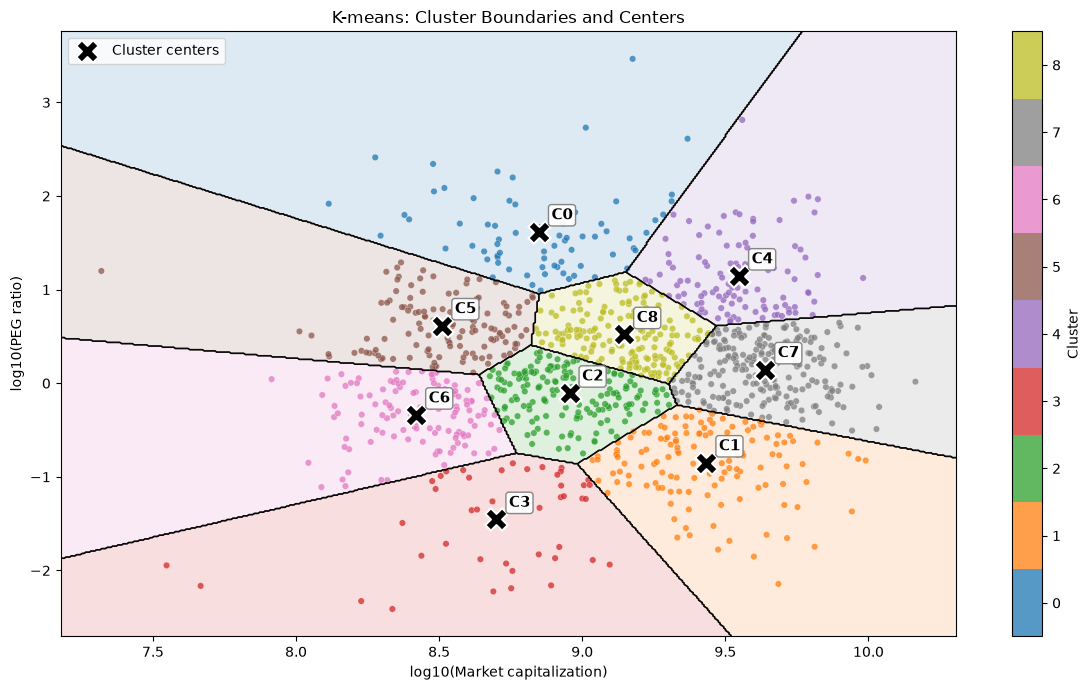

,Ticker,Market_capital,PEG ratio,Cluster
0,RLJ,2.023031e+09,4.680005,8
3,RRR,5.268382e+09,6.189660,4
4,IVT,2.478155e+09,2.987124,8
5,HOG,3.443334e+09,1.680040,7
6,FWRG,8.320736e+08,37.802195,0
8,IBP,5.633310e+09,1.506817,7
9,RDNT,6.168862e+09,98.457005,4
10,KRG,5.084775e+09,0.233085,1
11,SBRA,5.492022e+09,88.989084,4
12,NTST,2.337401e+09,12.464000,4


In [14]:
from matplotlib.colors import ListedColormap

# Build a grid in log10 space and predict using the fitted scaler.
x = X_log["Market_capital"]
y = X_log["PEG ratio"]
x_pad = (x.max() - x.min()) * 0.05
y_pad = (y.max() - y.min()) * 0.05
xx, yy = np.meshgrid(
    np.linspace(x.min() - x_pad, x.max() + x_pad, 500),
    np.linspace(y.min() - y_pad, y.max() + y_pad, 500),
)
grid = pd.DataFrame(
    np.column_stack([xx.ravel(), yy.ravel()]),
    columns=X_log.columns,
)
regions = kmeans.predict(scaler.transform(grid)).reshape(xx.shape)
centers_log = scaler.inverse_transform(kmeans.cluster_centers_)
n_clusters = kmeans.n_clusters
cmap = ListedColormap(plt.get_cmap("tab10").colors[:n_clusters])

fig, ax = plt.subplots(figsize=(12, 7))

# Shade cluster regions and outline each region independently.
ax.contourf(
    xx, yy, regions,
    levels=np.arange(n_clusters + 1) - 0.5,
    cmap=cmap, alpha=0.15,
)
for cluster in range(n_clusters):
    mask = (regions == cluster).astype(float)
    if mask.min() != mask.max():
        ax.contour(
            xx, yy, mask, levels=[0.5],
            colors="black", linewidths=1.1, alpha=0.8,
        )

points = ax.scatter(
    x, y, c=stocks["Cluster"], cmap=cmap,
    vmin=-0.5, vmax=n_clusters - 0.5,
    s=22, alpha=0.75, edgecolors="white", linewidths=0.25,
)

ax.scatter(
    centers_log[:, 0], centers_log[:, 1],
    c="black", marker="X", s=260,
    edgecolors="white", linewidths=1.5,
    label="Cluster centers", zorder=5,
)
for cluster, (cx, cy) in enumerate(centers_log):
    ax.annotate(
        f"C{cluster}", (cx, cy), xytext=(9, 9),
        textcoords="offset points", fontsize=11, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="gray", alpha=0.95),
        zorder=6,
    )

ax.set(
    xlabel="log10(Market capitalization)",
    ylabel="log10(PEG ratio)",
    title="K-means: Cluster Boundaries and Centers",
    xlim=(xx.min(), xx.max()), ylim=(yy.min(), yy.max()),
)
fig.colorbar(points, ax=ax, ticks=range(n_clusters), label="Cluster")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

display(stocks.head(10))


## 4. KNN Labels and Evaluation Design

Explicitly choose K-means or Morningstar as the label source, then select the number of neighbors and evaluation method.
When KNN uses K-means labels, evaluation measures how well it reproduces the clustering rule; it does not measure Morningstar classification accuracy.
For holdout evaluation, split the data first, then fit transformations and relevant models on the training set to avoid data leakage.


In [ ]:
# TODO: Build KNN and document the label source, number of neighbors, and evaluation results.


## 5. New-Stock Classification and Output

Provide the same three input columns for a new stock. Verify consistent definitions and units, and apply the feature transformations fitted during training.
Report the predicted class, neighboring stocks, and an explanation. Document limitations if the new stock falls outside the training data range.
Result tables may include cluster and prediction columns; raw and cleaned inputs must retain only the three original columns.


In [ ]:
# TODO: Provide a new stock and save prediction results to OUTPUT_DIR.
